# Heart Disease Prediction — Exploratory Data Analysis

**Author:** Vyshnavi Sunil Kumar  
**Dataset:** Heart Failure Prediction (Kaggle / UCI)  
**Notebook:** 01 of 02 — EDA & Preprocessing

---

## Project Overview

Heart disease is one of the leading causes of death globally. Early and 
accurate prediction can significantly improve patient outcomes. This project 
builds a complete machine learning pipeline to predict whether a patient 
has heart disease based on clinical features such as age, chest pain type, 
cholesterol, and resting blood pressure.

This notebook covers **Exploratory Data Analysis (EDA)** and **Preprocessing** — 
the foundation of any machine learning project. No model can perform well 
without first understanding the data.

---

## Dataset Description

The dataset contains **918 patient records** with 11 input features and 
1 binary target variable:

| Feature | Type | Description |
|---|---|---|
| Age | Numeric | Patient age in years |
| Sex | Categorical | M = Male, F = Female |
| ChestPainType | Categorical | ATA, NAP, ASY, TA |
| RestingBP | Numeric | Resting blood pressure (mm Hg) |
| Cholesterol | Numeric | Serum cholesterol (mg/dL) |
| FastingBS | Binary | Fasting blood sugar > 120 mg/dL |
| RestingECG | Categorical | Normal, ST, LVH |
| MaxHR | Numeric | Maximum heart rate achieved |
| ExerciseAngina | Binary | Exercise-induced angina (Y/N) |
| Oldpeak | Numeric | ST depression induced by exercise |
| ST_Slope | Categorical | Up, Flat, Down |
| **HeartDisease** | **Binary** | **Target: 0 = No, 1 = Yes** |

## 1. Importing Libraries

Before any analysis, we import all the libraries needed for this project.

- **NumPy & Pandas** — data manipulation and numerical operations
- **Matplotlib & Seaborn** — data visualisation
- **Scikit-learn** — machine learning models, preprocessing, and evaluation
- **SciPy** — statistical tests (paired t-test in Notebook 02)

We also suppress warnings to keep the output clean, and set a consistent 
plot style using `sns.set_theme()` so all visualisations look uniform 
throughout the notebook.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')

print("All libraries loaded successfully!")

All libraries loaded successfully!


## 2. Loading the Dataset

We load the dataset using `pd.read_csv()` and immediately do a first inspection 
using `.shape` and `.head()`.

- **`.shape`** tells us how many rows (patients) and columns (features) we have
- **`.head()`** shows the first 5 rows so we can visually confirm the data 
  loaded correctly and understand what each column looks like

This is always the first step after loading — never assume the data looks 
the way you expect it to.

In [25]:
df = pd.read_csv('../data/heart.csv')

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (918, 12)

First 5 rows:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Understanding Data Types & Missing Values

Before any analysis or modelling, we must understand what we are working with.

**`df.info()`** tells us:
- The data type of each column (int, float, object)
- How many non-null values exist per column
- This helps us identify missing values and columns that need type conversion

**`df.isnull().sum()`** explicitly counts missing values per column — 
a dataset with hidden nulls will cause models to crash or silently produce 
wrong results.

**`df.describe()`** gives us summary statistics for all numeric columns:
- **mean vs median** — if they differ greatly, the distribution is skewed
- **min/max** — helps spot impossible values (e.g. blood pressure of 0)
- **std** — tells us how spread out the values are

This step is not optional — it is where we discover data quality problems 
before they become modelling problems.

In [27]:
print("Data types & non-null counts:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nBasic statistics:")
df.describe()

Data types & non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR     

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


## 4. Class Distribution & Data Quality Check

### Class Balance
In any classification problem, we must check whether the target classes 
are balanced. If one class dominates (e.g. 95% No Disease, 5% Has Disease), 
the model will learn to always predict the majority class and appear accurate 
while being useless.

We visualise this using both a bar chart and a pie chart to make the 
imbalance (or balance) immediately obvious.

### Suspicious Zero Values
During `df.describe()` we noticed:
- **RestingBP minimum = 0** — a resting blood pressure of 0 mm Hg is 
  biologically impossible. A living patient cannot have zero blood pressure.
- **Cholesterol minimum = 0** — serum cholesterol of 0 mg/dL is also 
  impossible in a living patient.

These zeros are not real measurements — they are missing values that were 
coded as 0, a common practice in older medical datasets. We must identify 
how many exist before deciding how to handle them. Leaving them in would 
corrupt our models, particularly distance-based ones like KNN.

Target class distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64

HeartDisease
1    55.3
0    44.7 %

--- Suspicious zeros ---
RestingBP == 0: 1 rows
Cholesterol == 0: 172 rows


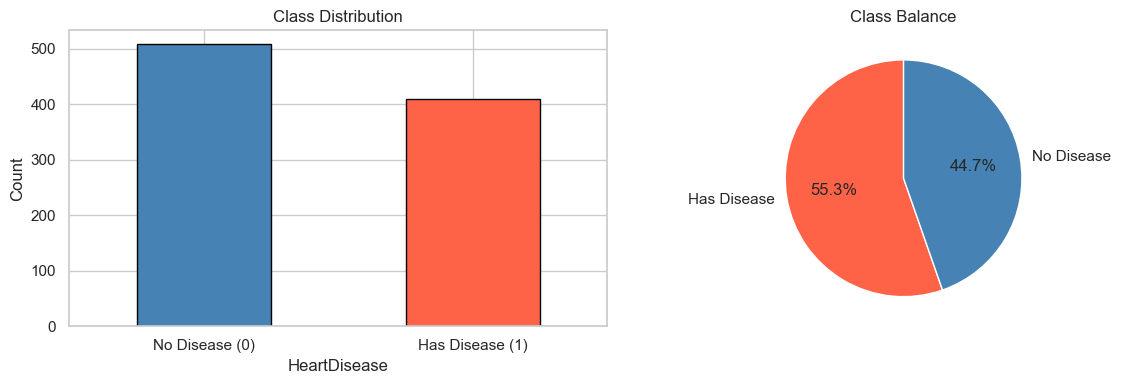

In [28]:
print("Target class distribution:")
print(df['HeartDisease'].value_counts())
print(f"\n{df['HeartDisease'].value_counts(normalize=True).mul(100).round(1).to_string()} %")

print("\n--- Suspicious zeros ---")
print(f"RestingBP == 0: {(df['RestingBP'] == 0).sum()} rows")
print(f"Cholesterol == 0: {(df['Cholesterol'] == 0).sum()} rows")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['HeartDisease'].value_counts().plot(kind='bar', ax=axes[0],
    color=['steelblue','tomato'], edgecolor='black')
axes[0].set_title('Class Distribution')
axes[0].set_xticklabels(['No Disease (0)', 'Has Disease (1)'], rotation=0)
axes[0].set_ylabel('Count')

axes[1].pie(df['HeartDisease'].value_counts(), labels=['Has Disease', 'No Disease'],
            autopct='%1.1f%%', colors=['tomato','steelblue'], startangle=90)
axes[1].set_title('Class Balance')

plt.tight_layout()
plt.show()

## 5. Data Cleaning

Based on our findings in the previous cell, we handle the two data quality 
issues before proceeding with any analysis.

### RestingBP — Drop 1 row
Only 1 patient has RestingBP = 0. Since it is a single row out of 918, 
dropping it loses less than 0.1% of our data — an acceptable trade-off 
for removing a corrupt record. Imputing a single row would not meaningfully 
change the dataset.

### Cholesterol — Impute with Median
172 patients (18.7% of the dataset) have Cholesterol = 0. This is too many 
rows to drop — we would lose nearly a fifth of our data, which would 
significantly reduce model performance and introduce bias.

Instead we **impute with the median** of non-zero values. We use the median 
rather than the mean because:
- The median is resistant to outliers (Cholesterol has a long right tail 
  as seen in the distribution plots)
- The mean would be pulled upward by extreme values like 603 mg/dL, 
  giving an unrealistic imputation value

Critically, we calculate the median **only from non-zero values** — 
including the zeros in the median calculation would artificially lower it.

After cleaning we verify that no zeros remain and confirm the final 
dataset shape.

In [29]:
# Drop the 1 row where RestingBP is 0
df = df[df['RestingBP'] != 0].reset_index(drop=True)
print(f"After dropping RestingBP==0: {df.shape}")

# Replace Cholesterol zeros with median of non-zero values
chol_median = df[df['Cholesterol'] != 0]['Cholesterol'].median()
df['Cholesterol'] = df['Cholesterol'].replace(0, chol_median)
print(f"Cholesterol zeros replaced with median: {chol_median}")

# Verify
print(f"\nRemaining Cholesterol zeros: {(df['Cholesterol'] == 0).sum()}")
print(f"Remaining RestingBP zeros: {(df['RestingBP'] == 0).sum()}")
print(f"\nFinal dataset shape: {df.shape}")

After dropping RestingBP==0: (917, 12)
Cholesterol zeros replaced with median: 237.0

Remaining Cholesterol zeros: 0
Remaining RestingBP zeros: 0

Final dataset shape: (917, 12)


## 6. Distribution of Numeric Features

Now that the data is clean, we visualise the distribution of each numeric 
feature using histograms.

For each feature we plot:
- **The histogram** — shows the shape of the distribution (normal, skewed, 
  bimodal)
- **The mean (red dashed line)** — arithmetic average, sensitive to outliers
- **The median (orange dashed line)** — middle value, resistant to outliers

### What to look for:
- If **mean ≈ median** → the distribution is roughly symmetric (normal-like)
- If **mean > median** → right skew (long tail on the right, pulled by 
  high outliers)
- If **mean < median** → left skew (long tail on the left)

### What we found:
- **Age & MaxHR** — roughly symmetric, mean ≈ median. These are 
  well-behaved features.
- **RestingBP & Cholesterol** — slight right skew. Cholesterol in 
  particular has a long tail up to 600 mg/dL.
- **Oldpeak** — heavily right skewed. Most patients have values near 0 
  with a few extreme cases up to 6.2. This tells us that ST depression 
  is absent or minimal in most patients, but when present it can be severe.

Understanding skewness matters because some models (like Linear Regression) 
assume normally distributed features. Tree-based models and KNN are less 
sensitive to this.

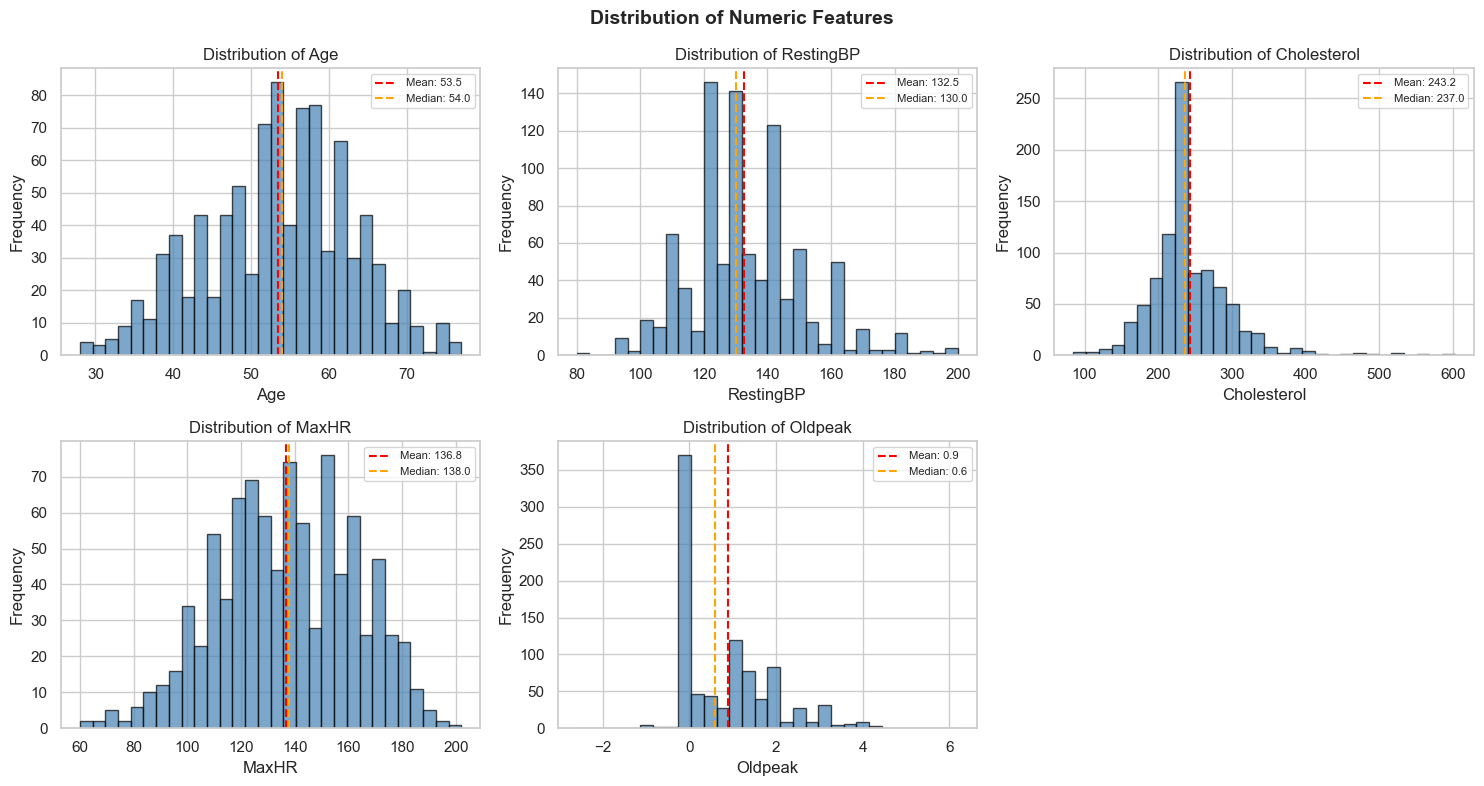

In [30]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].axvline(df[col].mean(), color='red', linestyle='--',
                    label=f'Mean: {df[col].mean():.1f}')
    axes[i].axvline(df[col].median(), color='orange', linestyle='--',
                    label=f'Median: {df[col].median():.1f}')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)

axes[5].set_visible(False)

plt.suptitle('Distribution of Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Categorical Features vs Heart Disease

Numeric distributions tell us about spread and shape, but categorical 
features require a different approach. Here we visualise how each 
categorical feature relates to the target variable (HeartDisease).

We plot the **percentage** of disease vs no disease within each category 
rather than raw counts. This is important because some categories have 
far more patients than others — using raw counts would be misleading.

### What we found:

**Sex:**
- Female patients have only ~25% heart disease rate
- Male patients have ~63% heart disease rate
- Sex is a meaningful predictor in this dataset

**ChestPainType:**
- ASY (Asymptomatic) → ~79% have heart disease — the most dangerous type 
  because patients feel no pain yet are at high risk
- ATA (Atypical Angina) → only ~15% have heart disease
- This is clinically significant — asymptomatic patients are often 
  under-diagnosed

**RestingECG:**
- ST abnormality → ~74% have heart disease
- LVH and Normal show moderate rates (~56% and ~51%)
- Less discriminative than other features

**ExerciseAngina:**
- Y (exercise-induced angina present) → ~85% have heart disease
- This is one of the strongest single predictors in the dataset

**ST_Slope:**
- Flat slope → ~82% have heart disease
- Down slope → ~79% have heart disease  
- Up slope → only ~20% have heart disease
- ST_Slope is the most visually discriminative categorical feature

These findings directly guide our feature importance analysis later — 
the features that show the strongest separation here will likely rank 
highest in our models.

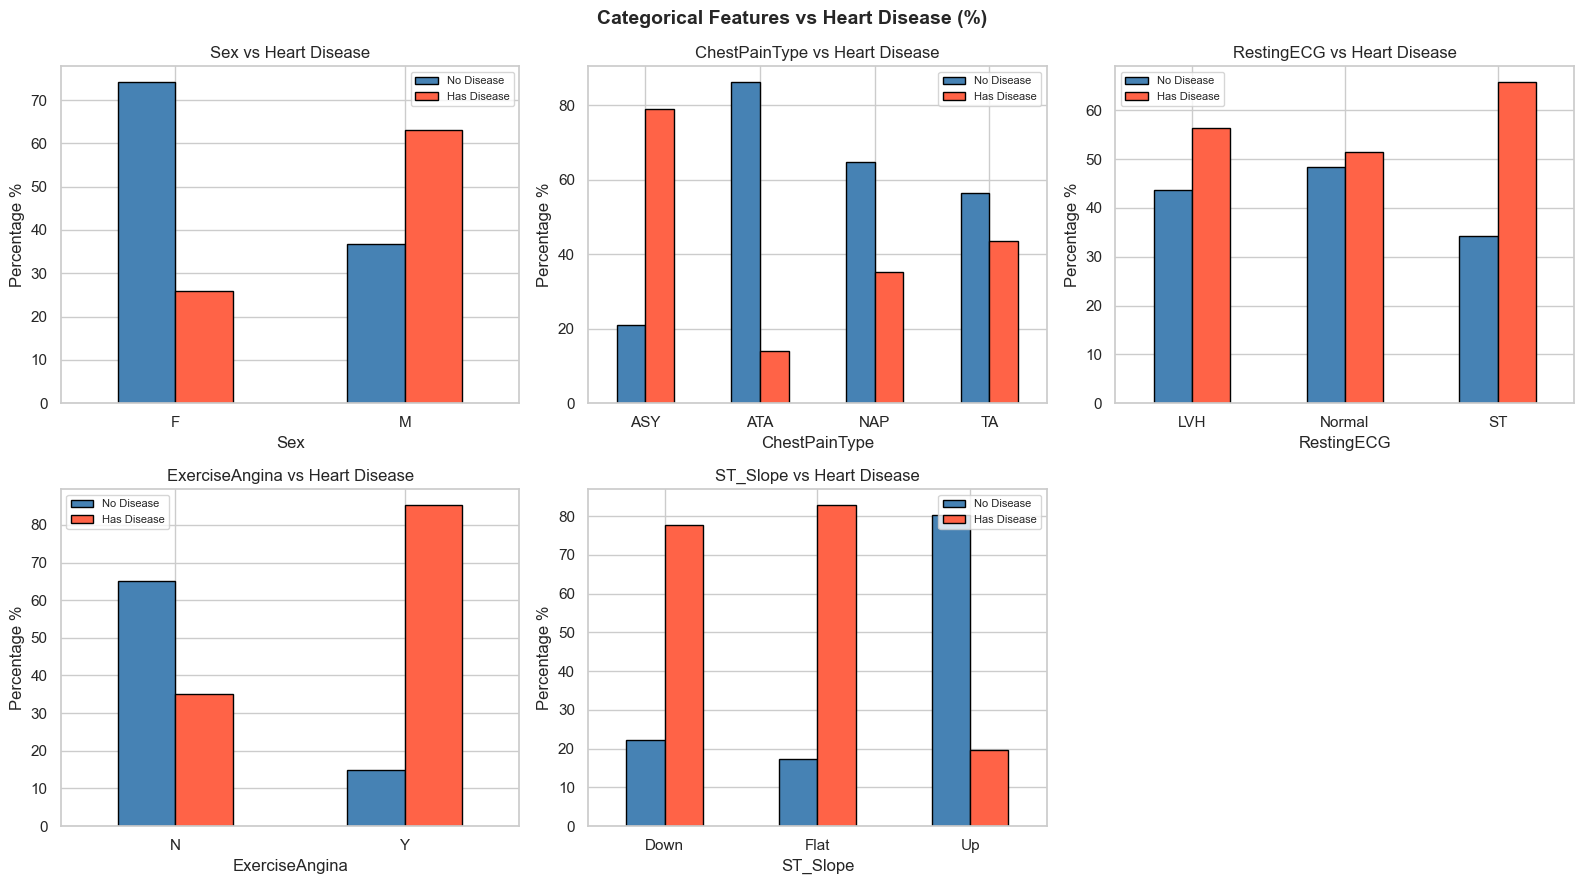

In [31]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = df.groupby(col)['HeartDisease'].value_counts(normalize=True).mul(100).unstack()
    ct.plot(kind='bar', ax=axes[i], color=['steelblue', 'tomato'], edgecolor='black')
    axes[i].set_title(f'{col} vs Heart Disease')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Percentage %')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=0)
    axes[i].legend(['No Disease', 'Has Disease'], fontsize=8)

axes[5].set_visible(False)

plt.suptitle('Categorical Features vs Heart Disease (%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Correlation Analysis

A correlation heatmap shows us the **linear relationship** between numeric 
features and the target variable. Correlation values range from -1 to +1:

- **+1** — perfect positive relationship (as one increases, so does the other)
- **0** — no linear relationship
- **-1** — perfect negative relationship (as one increases, the other decreases)

We use a **lower triangle mask** to avoid duplicating information — each 
pair only needs to appear once.

We temporarily encode the two binary categorical columns (Sex and 
ExerciseAngina) as 0/1 so they can be included in the correlation matrix.

### What we found:

**Strongest positive correlations with HeartDisease:**
- **ExerciseAngina (0.50)** — the single strongest numeric predictor
- **Oldpeak (0.40)** — higher ST depression = higher disease risk
- **Sex/Male (0.31)** — males more at risk in this dataset
- **Age (0.28)** — older patients more at risk

**Strongest negative correlations with HeartDisease:**
- **MaxHR (-0.40)** — lower maximum heart rate = higher disease risk. 
  This makes clinical sense — a diseased heart cannot achieve high rates 
  under stress

**Weak correlations:**
- **Cholesterol (0.08)** — surprisingly weak. This is likely because we 
  imputed 172 zero values with the median, which reduced the natural 
  variance of this feature
- **RestingBP (0.12)** — also weak as a standalone predictor

### Important limitation:
Correlation only captures **linear** relationships. A feature with low 
correlation may still be a powerful predictor in non-linear models like 
Decision Trees and Random Forests. We must not drop features based on 
correlation alone.

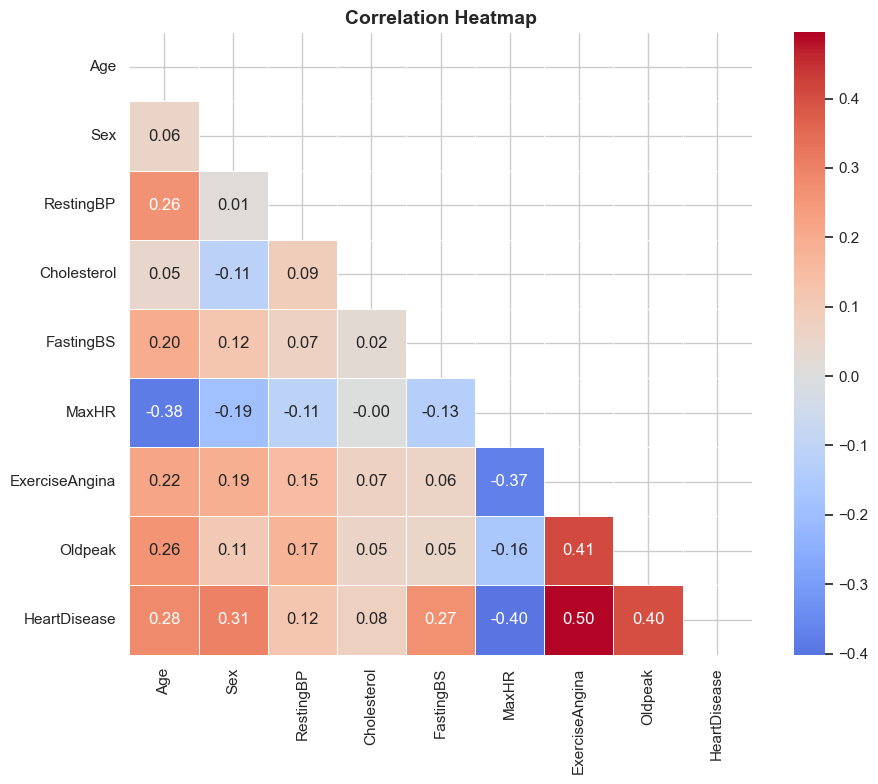


Top correlations with HeartDisease:
ExerciseAngina    0.495490
Oldpeak           0.403638
MaxHR            -0.401410
Sex               0.305118
Age               0.282012
FastingBS         0.267994
RestingBP         0.117990
Cholesterol       0.076262
Name: HeartDisease, dtype: float64


In [32]:
df_corr = df.copy()
df_corr['Sex'] = df_corr['Sex'].map({'M': 1, 'F': 0})
df_corr['ExerciseAngina'] = df_corr['ExerciseAngina'].map({'Y': 1, 'N': 0})

numeric_for_corr = ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS',
                    'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease']

corr_matrix = df_corr[numeric_for_corr].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nTop correlations with HeartDisease:")
print(corr_matrix['HeartDisease'].drop('HeartDisease').sort_values(
    key=abs, ascending=False))

## 9. Encoding & Preprocessing

Before we can feed data into any machine learning model, we must convert 
all features into numeric format. Models work with numbers — they cannot 
process text like "Male", "ATA", or "Flat" directly.

### Encoding Strategy

We use two different encoding approaches depending on the feature type:

**Binary Encoding** (for features with exactly 2 categories):
- `Sex`: M → 1, F → 0
- `ExerciseAngina`: Y → 1, N → 0

These have a natural binary interpretation so a single 0/1 column is sufficient.

**One-Hot Encoding** (for features with 3+ categories):
- `ChestPainType`: 4 categories → 4 new binary columns
- `RestingECG`: 3 categories → 3 new binary columns
- `ST_Slope`: 3 categories → 3 new binary columns

One-hot encoding creates a separate binary column for each category. 
We do NOT use label encoding (0, 1, 2...) for these because that would 
imply an ordinal relationship — as if "ASY" is somehow greater than "ATA" 
— which is meaningless for nominal categories.

### Feature Scaling

We apply **StandardScaler** which transforms each feature to have:
- Mean = 0
- Standard deviation = 1

This is essential for distance-based models like KNN (which measures 
distances between points) and Logistic Regression (which uses gradient 
descent). Without scaling, a feature like Age (range 28–77) would 
dominate over FastingBS (range 0–1) simply due to magnitude, not importance.

Note: Tree-based models (Decision Tree, Random Forest) do not require 
scaling, but applying it does not harm them either.

### Train/Test Split

We split 80% for training and 20% for testing with `stratify=y` to ensure 
the class balance (55/45) is preserved in both sets. Using `random_state=42` 
ensures the split is reproducible — anyone running this notebook gets 
identical results.

In [33]:
df_model = df.copy()

# Binary encoding
df_model['Sex'] = df_model['Sex'].map({'M': 1, 'F': 0})
df_model['ExerciseAngina'] = df_model['ExerciseAngina'].map({'Y': 1, 'N': 0})

# One-hot encoding
df_model = pd.get_dummies(df_model, columns=['ChestPainType', 'RestingECG', 'ST_Slope'],
                          drop_first=False)

print("Columns after encoding:")
print(df_model.columns.tolist())
print(f"\nShape: {df_model.shape}")

# Separate features and target
X = df_model.drop('HeartDisease', axis=1)
y = df_model['HeartDisease']

# Scale features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"\nClass balance in training set:")
print(y_train.value_counts())

# Save cleaned data for Notebook 02
df_model.to_csv('../data/heart_cleaned_encoded.csv', index=False)
print("\n✅ Cleaned encoded data saved to heart_cleaned_encoded.csv")

Columns after encoding:
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']

Shape: (917, 19)

Training set: (733, 18)
Test set:     (184, 18)

Class balance in training set:
HeartDisease
1    405
0    328
Name: count, dtype: int64

✅ Cleaned encoded data saved to heart_cleaned_encoded.csv


## 10. EDA Summary & Key Findings

This notebook completed the full exploratory data analysis and preprocessing 
pipeline. Below is a summary of every key finding before we proceed to 
modelling in Notebook 02.

---

### Data Quality
- Dataset had **no true missing values** but contained biologically 
  impossible zeros in RestingBP (1 row) and Cholesterol (172 rows)
- RestingBP zero was dropped; Cholesterol zeros were imputed with the 
  median of non-zero values (237.0 mg/dL)
- Final clean dataset: **917 rows, 12 features**

---

### Class Balance
- 55.3% Has Disease, 44.7% No Disease
- Dataset is **sufficiently balanced** — no need for oversampling techniques 
  like SMOTE

---

### Strongest Predictors (from correlation & visualisation)
| Feature | Relationship | Strength |
|---|---|---|
| ExerciseAngina | Positive | Strong (0.50) |
| Oldpeak | Positive | Strong (0.40) |
| MaxHR | Negative | Strong (-0.40) |
| ST_Slope | Categorical | Very strong (visual) |
| ChestPainType ASY | Categorical | Strong (visual) |
| Sex (Male) | Positive | Moderate (0.31) |
| Cholesterol | Positive | Weak (0.08) |

---

### Preprocessing Applied
- Binary encoding: Sex, ExerciseAngina
- One-hot encoding: ChestPainType, RestingECG, ST_Slope
- StandardScaler applied to all 18 features
- 80/20 stratified train/test split (733 train, 184 test)

---

### Next Steps
Notebook 02 will use this preprocessed data to build, tune and compare 
seven machine learning models:
- Clustering (K-Means, Hierarchical)
- Linear Regression
- Logistic Regression
- KNN
- Decision Tree
- Random Forest + Gradient Boosting
- Naive Bayes
- Neural Network (MLP)

Final model selection will be based on 5-fold cross-validation accuracy 
and paired t-tests for statistical significance.